In [1]:
# ==============================================================================
# Membros:
# - Guilherme Silva Dias (RA: 10427415)
# - Raffael Rodrigues Esteves (RA: 10420414)
# - Ricardo Carvalho Paixa Brandão (RA: 10376918)
#
# Síntese do conteúdo
# Análise Exploratória de Dados (EDA) e preparação do dataset "Abandono 
# Escolar por Renda Média (Brasil 2013-2023)". 
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
import warnings
warnings.filterwarnings('ignore')

In [2]:
# 1. Carregando os dados
caminho_arquivo = 'AbandonoEscolar_RendaMedia_2013_2023.csv' 

try:
    df = pd.read_csv(caminho_arquivo)
    print("✅ Dataset carregado com sucesso!\n")
    print(f"O dataset possui {df.shape[0]} linhas e {df.shape[1]} colunas.")
except FileNotFoundError:
    print(f"❌ Erro: O arquivo {caminho_arquivo} não foi encontrado.")

✅ Dataset carregado com sucesso!

O dataset possui 90160 linhas e 8 colunas.


In [3]:
# 2. Inspeção Inicial
print("Visão geral das primeiras linhas:")
display(df.head())

print("\nEstatísticas Descritivas:")
display(df.describe())

print("\nVerificação de Valores Nulos por Coluna:")
display(df.isnull().sum())

print("\nTipos de Dados por Coluna:")
display(df.dtypes)

Visão geral das primeiras linhas:


,Ano,Unidade_Geografica,Regiao,Localizacao,Dependencia_Administrativa,Grupo_de_Abandono,Taxa_Abandono,Renda_Media
0,2013,Norte,Brasil,Total,Total,Ensino Fundamental,4.0,2252
1,2013,Norte,Brasil,Total,Pública,Ensino Fundamental,4.3,2252
2,2013,Norte,Brasil,Total,Privada,Ensino Fundamental,0.3,2252
3,2013,Norte,Brasil,Total,Municipal,Ensino Fundamental,4.3,2252
4,2013,Norte,Brasil,Total,Federal,Ensino Fundamental,0.0,2252



Estatísticas Descritivas:


,Ano,Taxa_Abandono,Renda_Media
count,90160.000000,82112.000000,90160.000000
mean,2018.005435,2.585039,2637.198447
std,3.161136,3.716334,664.789964
min,2013.000000,0.000000,1507.000000
25%,2015.000000,0.300000,2091.000000
50%,2018.000000,1.200000,2531.000000
75%,2021.000000,3.400000,3093.500000
max,2023.000000,100.000000,5347.000000



Verificação de Valores Nulos por Coluna:


Ano                              0
Unidade_Geografica               0
Regiao                           0
Localizacao                      0
Dependencia_Administrativa       0
Grupo_de_Abandono                0
Taxa_Abandono                 8048
Renda_Media                      0
dtype: int64


Tipos de Dados por Coluna:


Ano                             int64
Unidade_Geografica                str
Regiao                            str
Localizacao                       str
Dependencia_Administrativa        str
Grupo_de_Abandono                 str
Taxa_Abandono                 float64
Renda_Media                     int64
dtype: object

In [4]:
# --- 3. LIMPEZA E PREPARAÇÃO DOS DADOS ---
# Criação de um dataframe limpo, removendo linhas onde os dados cruciais estão ausentes
df_clean = df.dropna(subset=['Taxa_Abandono', 'Renda_Media']).copy()

# Opcional: Se houver necessidade de converter alguma coluna para número
# df_clean['Taxa_Abandono'] = pd.to_numeric(df_clean['Taxa_Abandono'], errors='coerce')

print(f"Total de registros após a limpeza: {df_clean.shape[0]}")

# Verificação de valores nulos no dataframe limpo
print("\nVerificação de Valores Nulos no DataFrame Limpo:")
display(df_clean.isnull().sum())

Total de registros após a limpeza: 82112

Verificação de Valores Nulos no DataFrame Limpo:


Ano                           0
Unidade_Geografica            0
Regiao                        0
Localizacao                   0
Dependencia_Administrativa    0
Grupo_de_Abandono             0
Taxa_Abandono                 0
Renda_Media                   0
dtype: int64

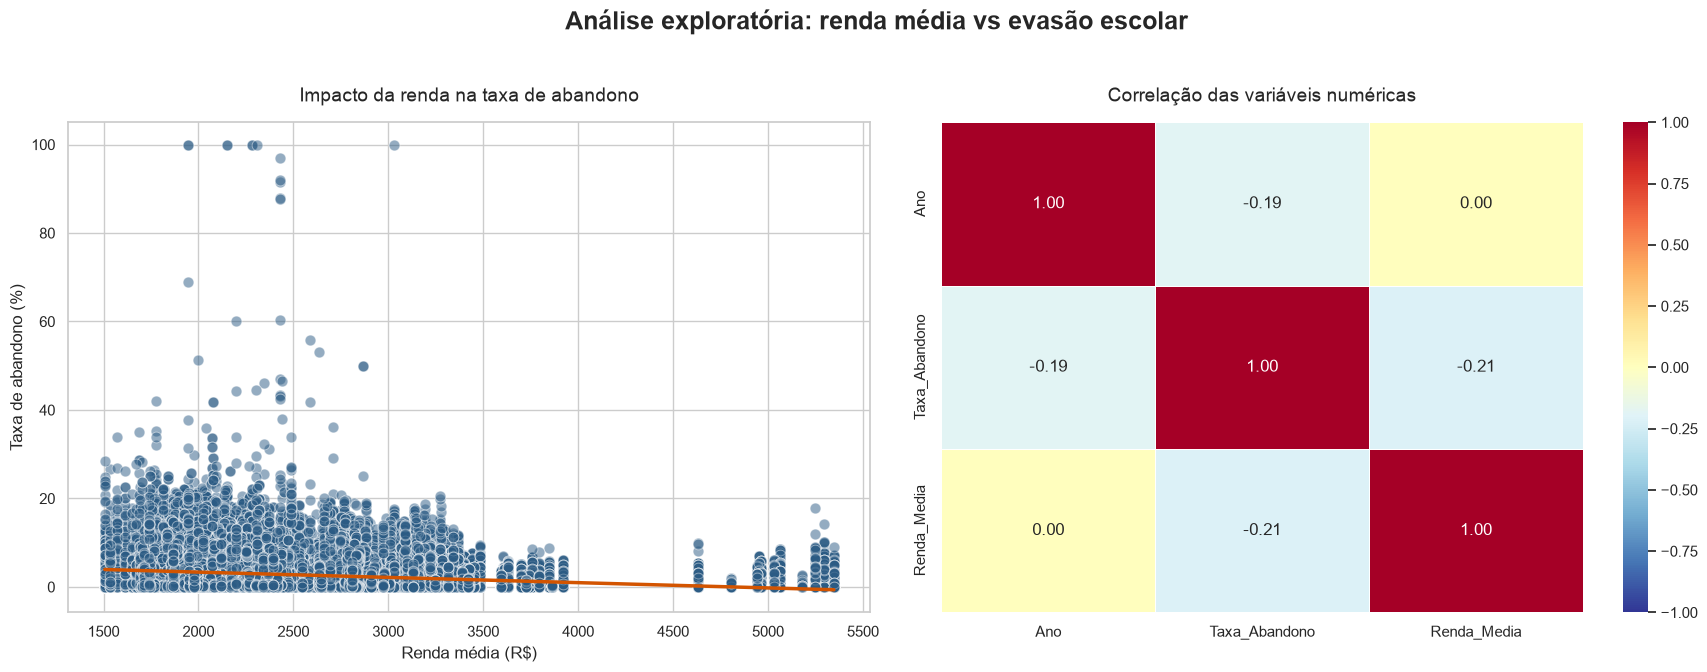

In [5]:
# 4. Análise exploratória

# Criando a figura e os eixos
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Análise exploratória: renda média vs evasão escolar', fontsize=18, fontweight='bold')

# Gráfico 1: Dispersão e tendência (Esquerda)
sns.scatterplot(
    data=df_clean, x='Renda_Media', y='Taxa_Abandono', 
    alpha=0.5, color='#2B5B84', s=60, ax=axes[0]
)
sns.regplot(
    data=df_clean, x='Renda_Media', y='Taxa_Abandono', 
    scatter=False, color='#D35400', line_kws={"linewidth": 2.5}, ax=axes[0]
)

axes[0].set_title('Impacto da renda na taxa de abandono', fontsize=14, pad=15)
axes[0].set_xlabel('Renda média (R$)', fontsize=12)
axes[0].set_ylabel('Taxa de abandono (%)', fontsize=12)

# Gráfico 2: Matriz de correlação (Direita)
colunas_numericas = df_clean.select_dtypes(include=[np.number])
matriz_corr = colunas_numericas.corr()

sns.heatmap(
    matriz_corr, annot=True, cmap='RdYlBu_r', fmt=".2f", 
    vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 12}, ax=axes[1]
)

axes[1].set_title('Correlação das variáveis numéricas', fontsize=14, pad=15)
plt.tight_layout(pad=2.0)
plt.show()

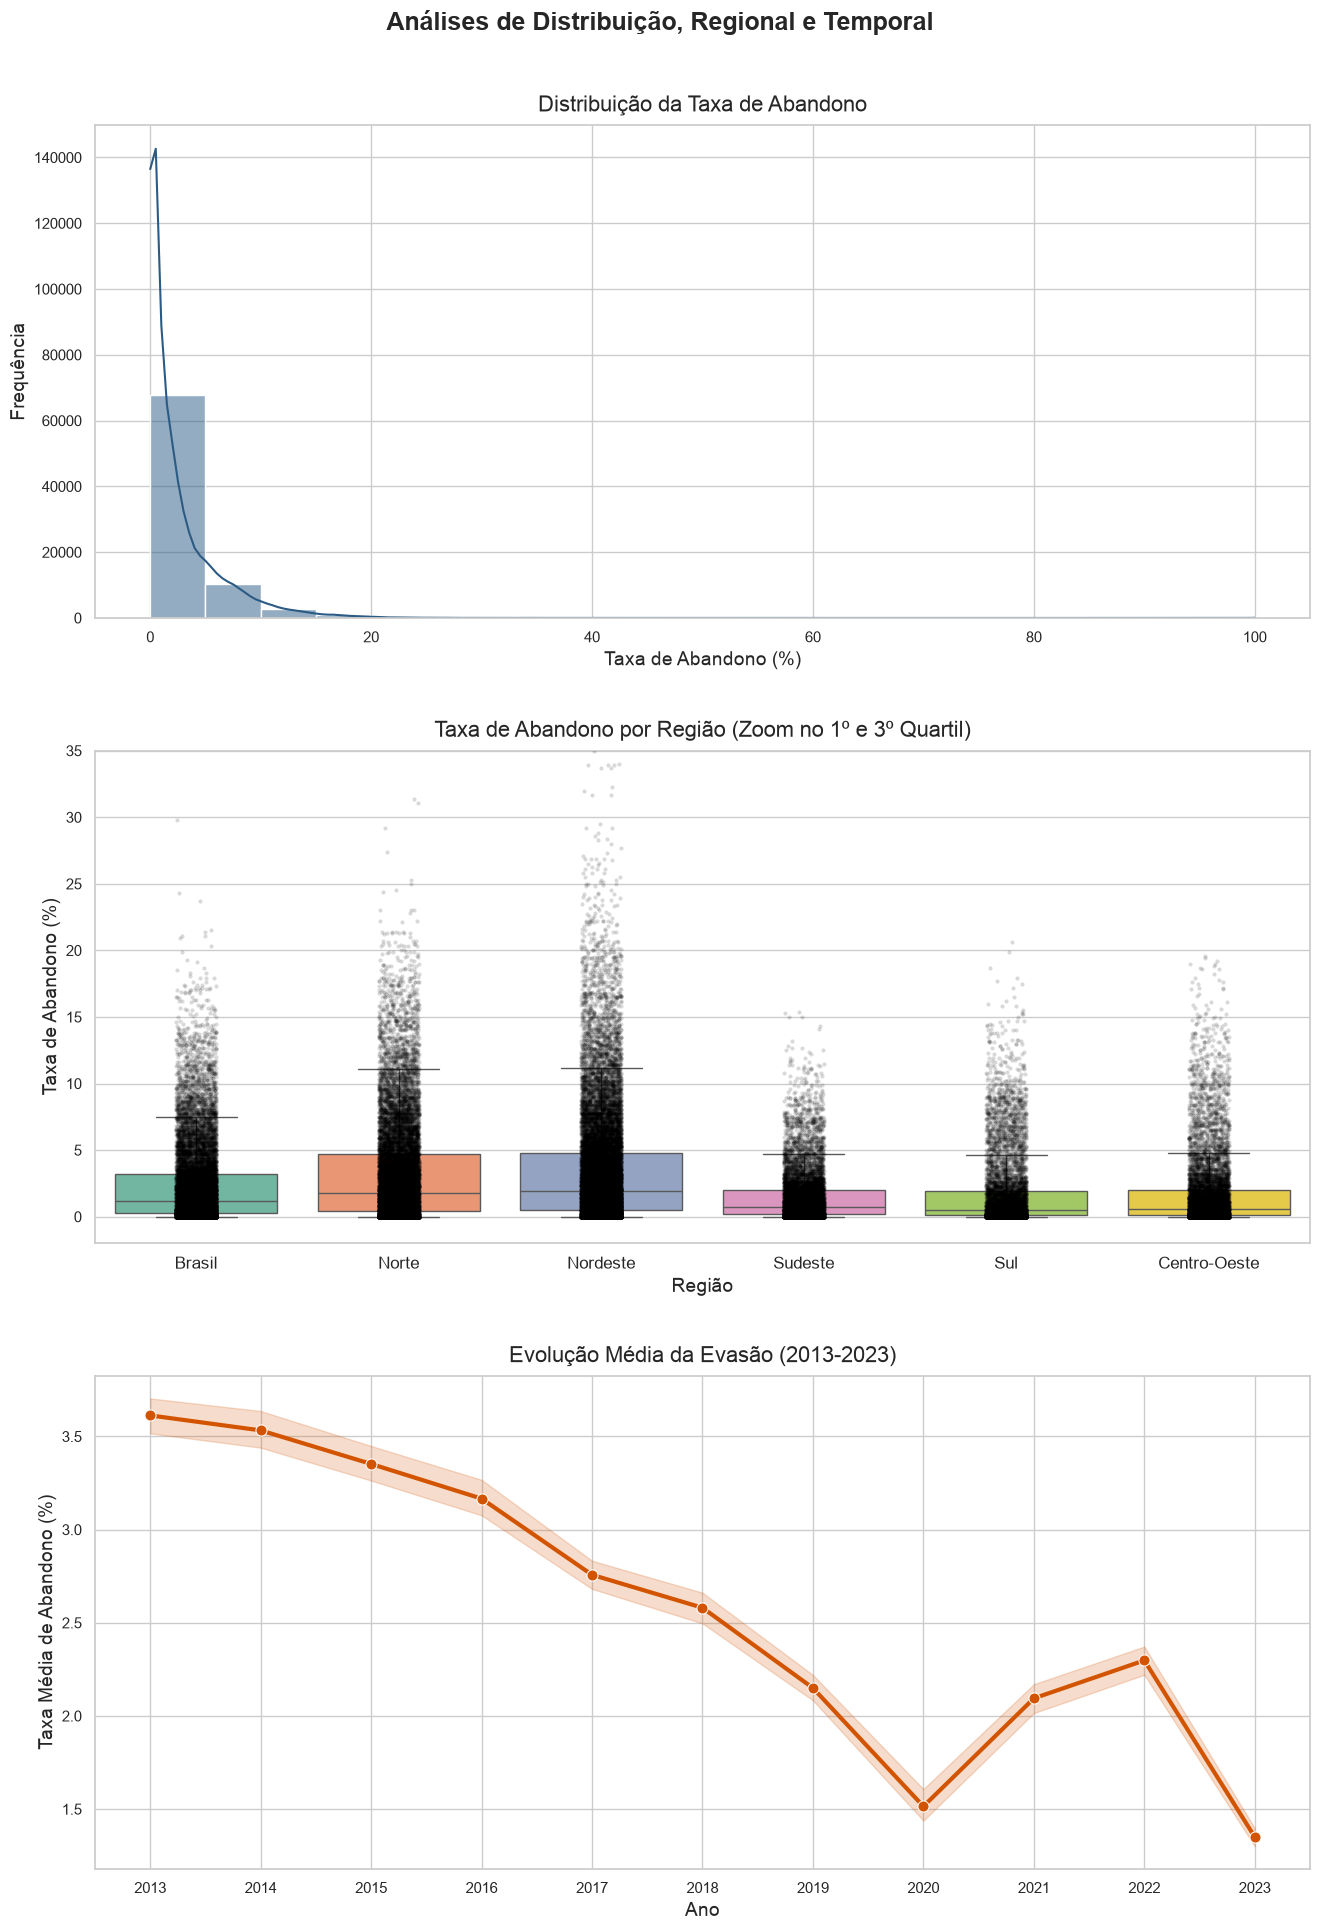

In [6]:
# 5. Análise exploratória temporal

fig, axes = plt.subplots(3, 1, figsize=(14, 20))
fig.suptitle('Análises de Distribuição, Regional e Temporal', fontsize=18, fontweight='bold', y=0.98)

# Gráfico 1: Histograma da taxa de abandono
sns.histplot(
    data=df_clean, x='Taxa_Abandono', kde=True, 
    color='#2B5B84', bins=20, ax=axes[0]
)
axes[0].set_title('Distribuição da Taxa de Abandono', fontsize=16, pad=10)
axes[0].set_xlabel('Taxa de Abandono (%)', fontsize=14)
axes[0].set_ylabel('Frequência', fontsize=14)

# Gráfico 2: Boxplot por região 
nome_coluna_regiao = 'Regiao' if 'Regiao' in df_clean.columns else 'Unidade_Geografica'

sns.boxplot(
    data=df_clean, x=nome_coluna_regiao, y='Taxa_Abandono', 
    palette='Set2', 
    showfliers=False,  
    ax=axes[1]
)

sns.stripplot(
    data=df_clean, x=nome_coluna_regiao, y='Taxa_Abandono', 
    color='black', alpha=0.15, jitter=True, size=3, ax=axes[1]
)

axes[1].set_title('Taxa de Abandono por Região (Zoom no 1º e 3º Quartil)', fontsize=16, pad=10)
axes[1].set_xlabel('Região', fontsize=14)
axes[1].set_ylabel('Taxa de Abandono (%)', fontsize=14)
axes[1].tick_params(axis='x', rotation=0, labelsize=12)
axes[1].set_ylim(-2, 35)

# Gráfico 3: Evolução temporal
sns.lineplot(
    data=df_clean, x='Ano', y='Taxa_Abandono', 
    estimator='mean', color='#D35400', linewidth=3, marker='o', markersize=8, ax=axes[2]
)
axes[2].set_title('Evolução Média da Evasão (2013-2023)', fontsize=16, pad=10)
axes[2].set_xlabel('Ano', fontsize=14)
axes[2].set_ylabel('Taxa Média de Abandono (%)', fontsize=14)
axes[2].set_xticks(df_clean['Ano'].unique()) # Força a mostrar todos os anos no eixo X

plt.tight_layout(pad=3.0)
plt.show()

In [9]:
# 6. Preparando para o ML
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Variável independente (X) e dependente (y)
X = df_clean[['Renda_Media']]
y = df_clean['Taxa_Abandono']

# Divisão em Treino (70%) e Teste (30%) conforme a metodologia
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Base de Treino: {X_train.shape[0]} registros")
print(f"Base de Teste: {X_test.shape[0]} registros\n")

# 7. Treinando os modelos

# Modelo 1: Regressão Linear
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)
y_pred_lr = modelo_lr.predict(X_test)

# Modelo 2: Árvore de Decisão (limitamos a profundidade para evitar overfitting)
modelo_dt = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_dt.fit(X_train, y_train)
y_pred_dt = modelo_dt.predict(X_test)

# 8. Avaliação de desempenho

def avaliar_modelo(nome, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    
    print(f"--- Desempenho: {nome} ---")
    print(f"MSE (Erro Quadrático Médio): {mse:.4f}")
    print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.4f}")
    print(f"R² (Coeficiente de Determinação): {r2:.4f}\n")

avaliar_modelo("Regressão Linear", y_test, y_pred_lr)
avaliar_modelo("Árvore de Decisão", y_test, y_pred_dt)

Base de Treino: 57478 registros
Base de Teste: 24634 registros

--- Desempenho: Regressão Linear ---
MSE (Erro Quadrático Médio): 13.3227
RMSE (Raiz do Erro Quadrático Médio): 3.6500
R² (Coeficiente de Determinação): 0.0447

--- Desempenho: Árvore de Decisão ---
MSE (Erro Quadrático Médio): 12.9879
RMSE (Raiz do Erro Quadrático Médio): 3.6039
R² (Coeficiente de Determinação): 0.0687

